In [1]:

!pip install chembl_webresource_client


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [chembl_webresource_client]


In [2]:

from chembl_webresource_client.new_client import new_client

target = new_client.target

targets = target.filter(
    pref_name__icontains="epidermal growth factor receptor",
    organism="Homo sapiens"
).only([
    "target_chembl_id",
    "pref_name",
    "organism",
    "target_type"
])

target_df = pd.DataFrame(list(targets))

print(target_df.head(10))


/usr/local/lib/python3.13/dist-packages/chembl_webresource_client/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __version__ = __import__('pkg_resources').get_distribution('chembl_webresource_client').version


NameError: name 'pd' is not defined

In [3]:

import pandas as pd

print("Pandas is ready!")


Pandas is ready!


In [4]:
from chembl_webresource_client.new_client import new_client

In [5]:
print(pd.__version__)

2.2.3


In [7]:
from chembl_webresource_client.new_client import new_client

target = new_client.target

print("ChEMBL connected successfully!")

ChEMBL connected successfully!


In [8]:
targets = target.filter(
    pref_name__icontains="epidermal growth factor receptor",
    organism="Homo sapiens"
).only([
    "target_chembl_id",
    "pref_name",
    "organism",
    "target_type"
])

target_df = pd.DataFrame(list(targets))

display(target_df.head(10))

HttpApplicationError: Error for url https://www.ebi.ac.uk/chembl/api/data/target.json, server response: <!doctype html>
<html lang="en" class="vf-no-js">
  <head>
    <script>
// Detect if JS is on and swap vf-no-js for vf-js on the html element
(function(H){H.className=H.className.replace(/\bvf-no-js\b/,'vf-js')})(document.documentElement);
</script>

    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <!-- <link rel="stylesheet" media="all" href="/css/styles.css?" /> -->
    <title>Error: 500 | EMBLâs European Bionformatics Institute</title>



    <link rel="icon" type="image/x-icon"
  href="https://ebi.emblstatic.net/web_guidelines/EBI-Framework/v1.4/images/logos/EMBL-EBI/favicons/favicon.ico" />
<link rel="icon" type="image/png"
  href="https://ebi.emblstatic.net/web_guidelines/EBI-Framework/v1.4/images/logos/EMBL-EBI/favicons/favicon-32x32.png" />
<link rel="icon" type="image/png" sizes="192Ã192"
  href="https://ebi.emblsta

In [9]:

import requests

url = "https://www.ebi.ac.uk/chembl/api/data/target/CHEMBL203.json"

response = requests.get(url, timeout=30)

print("Status code:", response.status_code)

if response.status_code == 200:
    target_info = response.json()
    print("Target:", target_info.get("pref_name"))
    print("Target ID:", target_info.get("target_chembl_id"))
else:
    print("ChEMBL server is currently unavailable.")
    print(response.text[:300])


Status code: 500
ChEMBL server is currently unavailable.
<!doctype html>
<html lang="en" class="vf-no-js">
  <head>
    <script>
// Detect if JS is on and swap vf-no-js for vf-js on the html element
(function(H){H.className=H.className.replace(/\bvf-no-js\b/,'vf-js')})(document.documentElement);
</script>

    <meta charset="utf-8">
    <meta name="viewpo


In [10]:

import pandas as pd

activity_url = (
    "https://www.ebi.ac.uk/chembl/api/data/activity.json"
)

params = {
    "target_chembl_id": "CHEMBL203",
    "standard_type": "IC50",
    "limit": 100
}

response = requests.get(
    activity_url,
    params=params,
    timeout=30
)

if response.status_code == 200:
    activity_data = response.json()["activities"]
    activity_df = pd.DataFrame(activity_data)
    display(activity_df.head())
else:
    print("API error:", response.status_code)


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,32260,[],CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,None,None,BAO_0000190,...,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.041
1,None,None,32263,[],CHEMBL621151,Inhibition of autophosphorylation of human epi...,F,None,None,BAO_0000190,...,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.3
2,None,None,32265,[],CHEMBL615325,Inhibition of ligand-induced proliferation in ...,F,None,None,BAO_0000190,...,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,7.82
3,None,None,32267,[],CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,None,None,BAO_0000190,...,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.17
4,None,None,32270,[],CHEMBL621151,Inhibition of autophosphorylation of human epi...,F,None,None,BAO_0000190,...,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.04


In [12]:

import requests
import pandas as pd

activity_url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

params = {
    "target_chembl_id": "CHEMBL203",
    "standard_type": "IC50",
    "limit": 100
}

response = requests.get(
    activity_url,
    params=params,
    timeout=30
)

print("Status:", response.status_code)

if response.status_code == 200:
    activity_data = response.json()["activities"]
    activity_df = pd.DataFrame(activity_data)

    print("Total records retrieved:", len(activity_df))
    display(activity_df.head())
else:
    print("Request failed:", response.text[:300])


Status: 500
Request failed: <!doctype html>
<html lang="en" class="vf-no-js">
  <head>
    <script>
// Detect if JS is on and swap vf-no-js for vf-js on the html element
(function(H){H.className=H.className.replace(/\bvf-no-js\b/,'vf-js')})(document.documentElement);
</script>

    <meta charset="utf-8">
    <meta name="viewpo


In [13]:

important_columns = [
    "molecule_chembl_id",
    "standard_type",
    "standard_value",
    "standard_units",
    "target_chembl_id",
    "assay_chembl_id",
    "pchembl_value"
]

clean_df = activity_df[
    [col for col in important_columns if col in activity_df.columns]
].copy()

display(clean_df.head(10))


,molecule_chembl_id,standard_type,standard_value,standard_units,target_chembl_id,assay_chembl_id,pchembl_value
0,CHEMBL68920,IC50,41.0,nM,CHEMBL203,CHEMBL674637,7.39
1,CHEMBL68920,IC50,300.0,nM,CHEMBL203,CHEMBL621151,6.52
2,CHEMBL68920,IC50,7820.0,nM,CHEMBL203,CHEMBL615325,5.11
3,CHEMBL69960,IC50,170.0,nM,CHEMBL203,CHEMBL674637,6.77
4,CHEMBL69960,IC50,40.0,nM,CHEMBL203,CHEMBL621151,7.40
5,CHEMBL69960,IC50,440.0,nM,CHEMBL203,CHEMBL615325,6.36
6,CHEMBL137635,IC50,9300.0,nM,CHEMBL203,CHEMBL677833,5.03
7,CHEMBL306988,IC50,500000.0,nM,CHEMBL203,CHEMBL674643,None
8,CHEMBL66879,IC50,3000000.0,nM,CHEMBL203,CHEMBL674643,None
9,CHEMBL77085,IC50,96000.0,nM,CHEMBL203,CHEMBL674643,4.02


In [14]:
print("Dataset shape:", activity_df.shape)

print("\nColumn names:")
print(activity_df.columns.tolist())

print("\nFirst 5 records:")
display(activity_df.head())

print("\nMissing values:")
display(activity_df.isnull().sum())

Dataset shape: (100, 47)

Column names:
['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'target_chembl_id', 'target_organism', 'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type', 'units', 'uo_units', 'upper_value', 'value']

First 5 records:


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,32260,[],CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,None,None,BAO_0000190,...,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.041
1,None,None,32263,[],CHEMBL621151,Inhibition of autophosphorylation of human epi...,F,None,None,BAO_0000190,...,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.3
2,None,None,32265,[],CHEMBL615325,Inhibition of ligand-induced proliferation in ...,F,None,None,BAO_0000190,...,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,7.82
3,None,None,32267,[],CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,None,None,BAO_0000190,...,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.17
4,None,None,32270,[],CHEMBL621151,Inhibition of autophosphorylation of human epi...,F,None,None,BAO_0000190,...,Homo sapiens,Epidermal growth factor receptor,9606,None,None,IC50,uM,UO_0000065,None,0.04



Missing values:


,0
action_type,100
activity_comment,96
activity_id,0
activity_properties,0
assay_chembl_id,0
assay_description,0
assay_type,0
assay_variant_accession,100
assay_variant_mutation,100
bao_endpoint,0


In [15]:
important_columns = [
    "molecule_chembl_id",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "target_chembl_id",
    "assay_chembl_id",
    "pchembl_value"
]

clean_df = activity_df[
    [col for col in important_columns if col in activity_df.columns]
].copy()

display(clean_df.head(10))

,molecule_chembl_id,standard_type,standard_relation,standard_value,standard_units,target_chembl_id,assay_chembl_id,pchembl_value
0,CHEMBL68920,IC50,=,41.0,nM,CHEMBL203,CHEMBL674637,7.39
1,CHEMBL68920,IC50,=,300.0,nM,CHEMBL203,CHEMBL621151,6.52
2,CHEMBL68920,IC50,=,7820.0,nM,CHEMBL203,CHEMBL615325,5.11
3,CHEMBL69960,IC50,=,170.0,nM,CHEMBL203,CHEMBL674637,6.77
4,CHEMBL69960,IC50,=,40.0,nM,CHEMBL203,CHEMBL621151,7.40
5,CHEMBL69960,IC50,=,440.0,nM,CHEMBL203,CHEMBL615325,6.36
6,CHEMBL137635,IC50,=,9300.0,nM,CHEMBL203,CHEMBL677833,5.03
7,CHEMBL306988,IC50,=,500000.0,nM,CHEMBL203,CHEMBL674643,None
8,CHEMBL66879,IC50,=,3000000.0,nM,CHEMBL203,CHEMBL674643,None
9,CHEMBL77085,IC50,=,96000.0,nM,CHEMBL203,CHEMBL674643,4.02


In [16]:
print(clean_df["standard_units"].value_counts(dropna=False))

standard_units
nM    100
Name: count, dtype: int64


In [17]:
clean_df["standard_value"] = pd.to_numeric(
    clean_df["standard_value"],
    errors="coerce"
)

clean_df["pchembl_value"] = pd.to_numeric(
    clean_df["pchembl_value"],
    errors="coerce"
)

In [18]:
clean_df = clean_df.dropna(
    subset=["molecule_chembl_id", "standard_value", "standard_units"]
)

clean_df = clean_df[
    (clean_df["standard_type"] == "IC50") &
    (clean_df["standard_relation"] == "=") &
    (clean_df["standard_units"] == "nM") &
    (clean_df["standard_value"] > 0)
].copy()

print("Records after cleaning:", len(clean_df))
display(clean_df.head())

Records after cleaning: 85


,molecule_chembl_id,standard_type,standard_relation,standard_value,standard_units,target_chembl_id,assay_chembl_id,pchembl_value
0,CHEMBL68920,IC50,=,41.0,nM,CHEMBL203,CHEMBL674637,7.39
1,CHEMBL68920,IC50,=,300.0,nM,CHEMBL203,CHEMBL621151,6.52
2,CHEMBL68920,IC50,=,7820.0,nM,CHEMBL203,CHEMBL615325,5.11
3,CHEMBL69960,IC50,=,170.0,nM,CHEMBL203,CHEMBL674637,6.77
4,CHEMBL69960,IC50,=,40.0,nM,CHEMBL203,CHEMBL621151,7.40


In [19]:
clean_df.to_csv("EGFR_IC50_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [20]:
import pandas as pd
import matplotlib.pyplot as plt

clean_df = pd.read_csv("EGFR_IC50_cleaned.csv")

print("Dataset size:", clean_df.shape)
display(clean_df.head())

Dataset size: (85, 8)


,molecule_chembl_id,standard_type,standard_relation,standard_value,standard_units,target_chembl_id,assay_chembl_id,pchembl_value
0,CHEMBL68920,IC50,=,41.0,nM,CHEMBL203,CHEMBL674637,7.39
1,CHEMBL68920,IC50,=,300.0,nM,CHEMBL203,CHEMBL621151,6.52
2,CHEMBL68920,IC50,=,7820.0,nM,CHEMBL203,CHEMBL615325,5.11
3,CHEMBL69960,IC50,=,170.0,nM,CHEMBL203,CHEMBL674637,6.77
4,CHEMBL69960,IC50,=,40.0,nM,CHEMBL203,CHEMBL621151,7.40


In [21]:
unique_compounds = clean_df["molecule_chembl_id"].nunique()

print("Total experimental records:", len(clean_df))
print("Unique compounds:", unique_compounds)

Total experimental records: 85
Unique compounds: 72


In [22]:
print("Mean IC50:", clean_df["standard_value"].mean(), "nM")
print("Median IC50:", clean_df["standard_value"].median(), "nM")
print("Minimum IC50:", clean_df["standard_value"].min(), "nM")
print("Maximum IC50:", clean_df["standard_value"].max(), "nM")

Mean IC50: 322641.0558823529 nM
Median IC50: 8400.0 nM
Minimum IC50: 0.45 nM
Maximum IC50: 6500000.0 nM


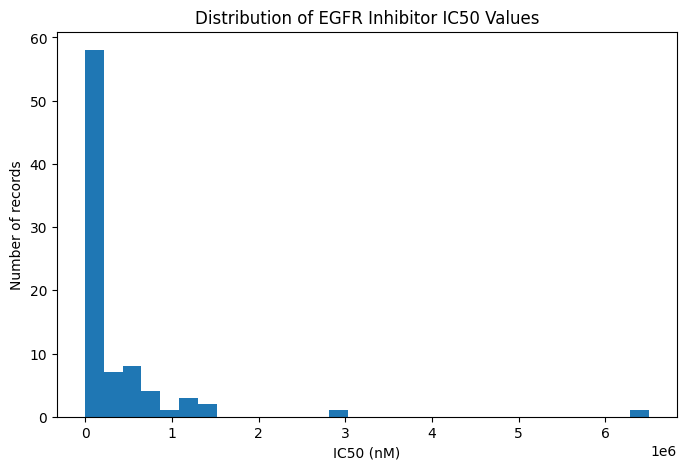

In [23]:
plt.figure(figsize=(8, 5))

plt.hist(clean_df["standard_value"], bins=30)

plt.xlabel("IC50 (nM)")
plt.ylabel("Number of records")
plt.title("Distribution of EGFR Inhibitor IC50 Values")

plt.show()

In [24]:
top_compounds = clean_df.sort_values(
    by="standard_value",
    ascending=True
)

display(
    top_compounds[
        ["molecule_chembl_id", "standard_value",
         "standard_units", "assay_chembl_id"]
    ].head(10)
)

,molecule_chembl_id,standard_value,standard_units,assay_chembl_id
15,CHEMBL304271,0.45,nM,CHEMBL674637
74,CHEMBL67003,1.80,nM,CHEMBL674637
83,CHEMBL305246,2.80,nM,CHEMBL674637
40,CHEMBL67057,4.50,nM,CHEMBL674637
73,CHEMBL308645,4.70,nM,CHEMBL674637
52,CHEMBL69629,6.50,nM,CHEMBL674637
79,CHEMBL134312,11.00,nM,CHEMBL677833
59,CHEMBL66570,13.00,nM,CHEMBL674637
27,CHEMBL136491,14.00,nM,CHEMBL677833
38,CHEMBL302552,22.00,nM,CHEMBL674637


In [25]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 56.3 MB/s  0:00:00


In [26]:
from rdkit import Chem
from rdkit.Chem import Descriptors

print("RDKit installed successfully!")

RDKit installed successfully!


In [27]:
from rdkit import Chem
from rdkit.Chem import Descriptors

smiles = "CC(=O)OC1=CC=CC=C1C(=O)O"

molecule = Chem.MolFromSmiles(smiles)

print("Molecular Weight:", Descriptors.MolWt(molecule))
print("LogP:", Descriptors.MolLogP(molecule))
print("H Bond Donors:", Descriptors.NumHDonors(molecule))
print("H Bond Acceptors:", Descriptors.NumHAcceptors(molecule))

Molecular Weight: 180.15899999999996
LogP: 1.3101
H Bond Donors: 1
H Bond Acceptors: 3


In [28]:
import requests
import pandas as pd

compound_ids = clean_df["molecule_chembl_id"].dropna().unique()

print("Unique compounds:", len(compound_ids))

Unique compounds: 72


In [29]:
chembl_id = compound_ids[0]

url = f"https://www.ebi.ac.uk/chembl/api/data/molecule/{chembl_id}.json"

response = requests.get(url, timeout=30)

print("Status:", response.status_code)

if response.status_code == 200:
    molecule_data = response.json()
    print("Compound:", chembl_id)
    print("Molecular structures:",
          molecule_data.get("molecule_structures"))

Status: 500


In [30]:
print("Compound ID:", compound_ids[0])
print("Status code:", response.status_code)
print("Error message:", response.text[:500])

Compound ID: CHEMBL68920
Status code: 500
Error message: <!doctype html>
<html lang="en" class="vf-no-js">
  <head>
    <script>
// Detect if JS is on and swap vf-no-js for vf-js on the html element
(function(H){H.className=H.className.replace(/\bvf-no-js\b/,'vf-js')})(document.documentElement);
</script>

    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <!-- <link rel="stylesheet" media="all" href="/css/styles.css?" /> -->
    <title>Error: 500 | EMBLâs European Bionformatics Institute</title


In [31]:
import requests
import time

chembl_id = compound_ids[0]

url = f"https://www.ebi.ac.uk/chembl/api/data/molecule/{chembl_id}.json"

for attempt in range(3):
    try:
        response = requests.get(url, timeout=30)
        print("Attempt:", attempt + 1)
        print("Status:", response.status_code)

        if response.status_code == 200:
            molecule_data = response.json()
            print(molecule_data.get("molecule_structures"))
            break

        time.sleep(3)

    except requests.exceptions.RequestException as error:
        print("Connection error:", error)
        time.sleep(3)

Attempt: 1
Status: 500
Attempt: 2
Status: 500
Attempt: 3
Status: 500


In [32]:
import requests

test_url = "https://www.ebi.ac.uk/chembl/api/data/molecule.json"

test_response = requests.get(
    test_url,
    params={"limit": 1},
    timeout=30
)

print("Status:", test_response.status_code)
print(test_response.text[:500])

Status: 500
<!doctype html>
<html lang="en" class="vf-no-js">
  <head>
    <script>
// Detect if JS is on and swap vf-no-js for vf-js on the html element
(function(H){H.className=H.className.replace(/\bvf-no-js\b/,'vf-js')})(document.documentElement);
</script>

    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <!-- <link rel="stylesheet" media="all" href="/css/styles.css?" /> -->
    <title>Error: 500 | EMBLâs European Bionformatics Institute</title


In [33]:
print("First compound ID:", compound_ids[0])
print("Total unique compounds:", len(compound_ids))

First compound ID: CHEMBL68920
Total unique compounds: 72


In [34]:
import requests

url = "https://www.ebi.ac.uk/chembl/api/data/status.json"

r = requests.get(url, timeout=30)

print("Status:", r.status_code)
print(r.text[:1000])

Status: 500
<!doctype html>
<html lang="en" class="vf-no-js">
  <head>
    <script>
// Detect if JS is on and swap vf-no-js for vf-js on the html element
(function(H){H.className=H.className.replace(/\bvf-no-js\b/,'vf-js')})(document.documentElement);
</script>

    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <!-- <link rel="stylesheet" media="all" href="/css/styles.css?" /> -->
    <title>Error: 500 | EMBLâs European Bionformatics Institute</title>



    <link rel="icon" type="image/x-icon"
  href="https://ebi.emblstatic.net/web_guidelines/EBI-Framework/v1.4/images/logos/EMBL-EBI/favicons/favicon.ico" />
<link rel="icon" type="image/png"
  href="https://ebi.emblstatic.net/web_guidelines/EBI-Framework/v1.4/images/logos/EMBL-EBI/favicons/favicon-32x32.png" />
<link rel="icon" type="image/png" sizes="192Ã192"
  href="https://ebi.emblstatic.net/web_guidelines/EBI-Framework/v1.4/images/logos/EMBL-EBI/favicons/android-chrome-192x

In [35]:
ids = ";".join(compound_ids[:3])

url = f"https://www.ebi.ac.uk/chembl/api/data/molecule/set/{ids}.json"

r = requests.get(url, timeout=30)

print("Status:", r.status_code)

if r.status_code == 200:
    print(r.json().keys())
else:
    print(r.text[:300])

Status: 500
<!doctype html>
<html lang="en" class="vf-no-js">
  <head>
    <script>
// Detect if JS is on and swap vf-no-js for vf-js on the html element
(function(H){H.className=H.className.replace(/\bvf-no-js\b/,'vf-js')})(document.documentElement);
</script>

    <meta charset="utf-8">
    <meta name="viewpo


In [36]:
import requests

url = "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/aspirin/property/MolecularWeight,CanonicalSMILES/JSON"

r = requests.get(url, timeout=30)

print("Status:", r.status_code)

if r.status_code == 200:
    print(r.json())
else:
    print(r.text[:300])

Status: 200
{'PropertyTable': {'Properties': [{'CID': 2244, 'MolecularWeight': '180.16', 'ConnectivitySMILES': 'CC(=O)OC1=CC=CC=C1C(=O)O'}]}}


In [37]:
import requests

url = "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/aspirin/property/MolecularWeight,CanonicalSMILES/JSON"

response = requests.get(url, timeout=30)

data = response.json()

properties = data["PropertyTable"]["Properties"][0]

print("Molecular Weight:", properties["MolecularWeight"])
print("Canonical SMILES:", properties["ConnectivitySMILES"])

Molecular Weight: 180.16
Canonical SMILES: CC(=O)OC1=CC=CC=C1C(=O)O


In [38]:
display(clean_df[["molecule_chembl_id"]].head(10))

,molecule_chembl_id
0,CHEMBL68920
1,CHEMBL68920
2,CHEMBL68920
3,CHEMBL69960
4,CHEMBL69960
5,CHEMBL69960
6,CHEMBL137635
7,CHEMBL306988
8,CHEMBL66879
9,CHEMBL77085


In [39]:
print(activity_df.columns.tolist())

['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'target_chembl_id', 'target_organism', 'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type', 'units', 'uo_units', 'upper_value', 'value']


In [40]:
name_columns = [
    col for col in ["molecule_chembl_id", "molecule_pref_name"]
    if col in activity_df.columns
]

display(activity_df[name_columns].head(10))

,molecule_chembl_id,molecule_pref_name
0,CHEMBL68920,None
1,CHEMBL68920,None
2,CHEMBL68920,None
3,CHEMBL69960,None
4,CHEMBL69960,None
5,CHEMBL69960,None
6,CHEMBL137635,None
7,CHEMBL306988,None
8,CHEMBL66879,COUMARIC ACID
9,CHEMBL77085,None


In [41]:
compound_name = activity_df["molecule_pref_name"].dropna().iloc[0]

print("Compound name:", compound_name)

Compound name: COUMARIC ACID


In [42]:
import requests

url = (
    "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/"
    + requests.utils.quote(compound_name)
    + "/property/MolecularWeight,CanonicalSMILES,InChIKey/JSON"
)

r = requests.get(url, timeout=30)

print("Status:", r.status_code)

if r.status_code == 200:
    print(r.json()["PropertyTable"]["Properties"][0])
else:
    print("Compound not found or request failed.")

Status: 200
{'CID': 637542, 'MolecularWeight': '164.16', 'ConnectivitySMILES': 'C1=CC(=CC=C1C=CC(=O)O)O', 'InChIKey': 'NGSWKAQJJWESNS-ZZXKWVIFSA-N'}


In [43]:
from rdkit import Chem
from rdkit.Chem import Descriptors

def calculate_descriptors(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "Molecular_Weight": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "H_Bond_Donors": Descriptors.NumHDonors(mol),
        "H_Bond_Acceptors": Descriptors.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol),
        "Rotatable_Bonds": Descriptors.NumRotatableBonds(mol)
    }

print("Descriptor function created successfully!")

Descriptor function created successfully!


In [44]:
smiles = properties["ConnectivitySMILES"]

result = calculate_descriptors(smiles)

print(result)

{'Molecular_Weight': 180.15899999999996, 'LogP': 1.3101, 'H_Bond_Donors': 1, 'H_Bond_Acceptors': 3, 'TPSA': 63.60000000000001, 'Rotatable_Bonds': 2}


In [45]:
egfr_compounds = (
    activity_df[["molecule_chembl_id", "molecule_pref_name"]]
    .dropna(subset=["molecule_pref_name"])
    .drop_duplicates()
    .head(10)
    .reset_index(drop=True)
)

display(egfr_compounds)

,molecule_chembl_id,molecule_pref_name
0,CHEMBL66879,COUMARIC ACID
1,CHEMBL76904,TYRPHOSTIN 23
2,CHEMBL1009,LEVODOPA
3,CHEMBL310798,TYRPHOSTIN 25
4,CHEMBL76602,alpha-CYANO-4-HYDROXYCINNAMIC ACID
5,CHEMBL42423,4-Nitrocatechol
6,CHEMBL47986,ERBSTATIN
7,CHEMBL441343,PARABEN
8,CHEMBL145,CAFFEIC ACID
9,CHEMBL77456,TYRPHOSTIN 1


In [46]:
import requests
import pandas as pd
import time

results = []

for _, row in egfr_compounds.iterrows():

    name = row["molecule_pref_name"]
    chembl_id = row["molecule_chembl_id"]

    url = (
        "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/"
        + requests.utils.quote(name)
        + "/property/MolecularWeight,CanonicalSMILES,InChIKey/JSON"
    )

    try:
        response = requests.get(url, timeout=30)

        if response.status_code == 200:
            compound = response.json()["PropertyTable"]["Properties"][0]

            results.append({
                "ChEMBL_ID": chembl_id,
                "Compound_Name": name,
                "PubChem_CID": compound.get("CID"),
                "SMILES": compound.get("ConnectivitySMILES"),
                "InChIKey": compound.get("InChIKey")
            })

        else:
            print("Not retrieved:", name, response.status_code)

    except requests.exceptions.RequestException as error:
        print("Error:", name, error)

    time.sleep(0.3)

structure_df = pd.DataFrame(results)

display(structure_df.head())
print("Structures retrieved:", len(structure_df))

Not retrieved: PARABEN 404


,ChEMBL_ID,Compound_Name,PubChem_CID,SMILES,InChIKey
0,CHEMBL66879,COUMARIC ACID,637542,C1=CC(=CC=C1C=CC(=O)O)O,NGSWKAQJJWESNS-ZZXKWVIFSA-N
1,CHEMBL76904,TYRPHOSTIN 23,2052,C1=CC(=C(C=C1C=C(C#N)C#N)O)O,VTJXFTPMFYAJJU-UHFFFAOYSA-N
2,CHEMBL1009,LEVODOPA,6047,C1=CC(=C(C=C1CC(C(=O)O)N)O)O,WTDRDQBEARUVNC-LURJTMIESA-N
3,CHEMBL310798,TYRPHOSTIN 25,2061,C1=C(C=C(C(=C1O)O)O)C=C(C#N)C#N,YZOFLYUAQDJWKV-UHFFFAOYSA-N
4,CHEMBL76602,alpha-CYANO-4-HYDROXYCINNAMIC ACID,2102,C1=CC(=CC=C1C=C(C#N)C(=O)O)O,AFVLVVWMAFSXCK-UHFFFAOYSA-N


Structures retrieved: 9


In [47]:
from rdkit import Chem
from rdkit.Chem import Descriptors

descriptor_results = []

for _, row in structure_df.iterrows():

    mol = Chem.MolFromSmiles(row["SMILES"])

    if mol is None:
        continue

    descriptor_results.append({
        "ChEMBL_ID": row["ChEMBL_ID"],
        "Compound_Name": row["Compound_Name"],
        "Molecular_Weight": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "H_Bond_Donors": Descriptors.NumHDonors(mol),
        "H_Bond_Acceptors": Descriptors.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol),
        "Rotatable_Bonds": Descriptors.NumRotatableBonds(mol)
    })

descriptor_df = pd.DataFrame(descriptor_results)

display(descriptor_df)

,ChEMBL_ID,Compound_Name,Molecular_Weight,LogP,H_Bond_Donors,H_Bond_Acceptors,TPSA,Rotatable_Bonds
0,CHEMBL66879,COUMARIC ACID,164.160,1.49000,2,2,57.53,2
1,CHEMBL76904,TYRPHOSTIN 23,186.170,1.52836,2,4,88.04,1
2,CHEMBL1009,LEVODOPA,197.190,0.05220,4,4,103.78,3
3,CHEMBL310798,TYRPHOSTIN 25,202.169,1.23396,3,5,108.27,1
4,CHEMBL76602,alpha-CYANO-4-HYDROXYCINNAMIC ACID,189.170,1.38378,2,3,81.32,2
5,CHEMBL42423,4-Nitrocatechol,155.109,1.00600,2,4,83.60,1
6,CHEMBL47986,ERBSTATIN,179.175,0.81450,3,3,69.56,3
7,CHEMBL145,CAFFEIC ACID,180.159,1.19560,3,3,77.76,2
8,CHEMBL77456,TYRPHOSTIN 1,184.198,2.12576,0,3,56.81,2


In [48]:
descriptor_df.to_csv(
    "EGFR_Molecular_Descriptors.csv",
    index=False
)

print("Descriptor dataset exported!")

Descriptor dataset exported!


In [49]:
ic50_df = clean_df.copy()

ic50_df = ic50_df.rename(columns={
    "molecule_chembl_id": "ChEMBL_ID",
    "standard_value": "IC50_nM"
})

display(ic50_df.head())

,ChEMBL_ID,standard_type,standard_relation,IC50_nM,standard_units,target_chembl_id,assay_chembl_id,pchembl_value
0,CHEMBL68920,IC50,=,41.0,nM,CHEMBL203,CHEMBL674637,7.39
1,CHEMBL68920,IC50,=,300.0,nM,CHEMBL203,CHEMBL621151,6.52
2,CHEMBL68920,IC50,=,7820.0,nM,CHEMBL203,CHEMBL615325,5.11
3,CHEMBL69960,IC50,=,170.0,nM,CHEMBL203,CHEMBL674637,6.77
4,CHEMBL69960,IC50,=,40.0,nM,CHEMBL203,CHEMBL621151,7.40


In [50]:
combined_df = pd.merge(
    ic50_df,
    descriptor_df,
    on="ChEMBL_ID",
    how="inner"
)

print("Combined dataset shape:", combined_df.shape)

display(combined_df.head(10))

Combined dataset shape: (7, 15)


,ChEMBL_ID,standard_type,standard_relation,IC50_nM,standard_units,target_chembl_id,assay_chembl_id,pchembl_value,Compound_Name,Molecular_Weight,LogP,H_Bond_Donors,H_Bond_Acceptors,TPSA,Rotatable_Bonds
0,CHEMBL66879,IC50,=,3000000.0,nM,CHEMBL203,CHEMBL674643,NaN,COUMARIC ACID,164.160,1.49000,2,2,57.53,2
1,CHEMBL76904,IC50,=,35000.0,nM,CHEMBL203,CHEMBL674643,4.46,TYRPHOSTIN 23,186.170,1.52836,2,4,88.04,1
2,CHEMBL1009,IC50,=,900000.0,nM,CHEMBL203,CHEMBL674643,NaN,LEVODOPA,197.190,0.05220,4,4,103.78,3
3,CHEMBL310798,IC50,=,3000.0,nM,CHEMBL203,CHEMBL674643,5.52,TYRPHOSTIN 25,202.169,1.23396,3,5,108.27,1
4,CHEMBL76602,IC50,=,165000.0,nM,CHEMBL203,CHEMBL674643,NaN,alpha-CYANO-4-HYDROXYCINNAMIC ACID,189.170,1.38378,2,3,81.32,2
5,CHEMBL47986,IC50,=,14000.0,nM,CHEMBL203,CHEMBL674643,4.85,ERBSTATIN,179.175,0.81450,3,3,69.56,3
6,CHEMBL145,IC50,=,1200000.0,nM,CHEMBL203,CHEMBL674643,NaN,CAFFEIC ACID,180.159,1.19560,3,3,77.76,2


In [51]:
import numpy as np

combined_df["pIC50"] = 9 - np.log10(
    combined_df["IC50_nM"]
)

display(
    combined_df[
        ["ChEMBL_ID", "IC50_nM", "pIC50"]
    ].head(10)
)

,ChEMBL_ID,IC50_nM,pIC50
0,CHEMBL66879,3000000.0,2.522879
1,CHEMBL76904,35000.0,4.455932
2,CHEMBL1009,900000.0,3.045757
3,CHEMBL310798,3000.0,5.522879
4,CHEMBL76602,165000.0,3.782516
5,CHEMBL47986,14000.0,4.853872
6,CHEMBL145,1200000.0,2.920819


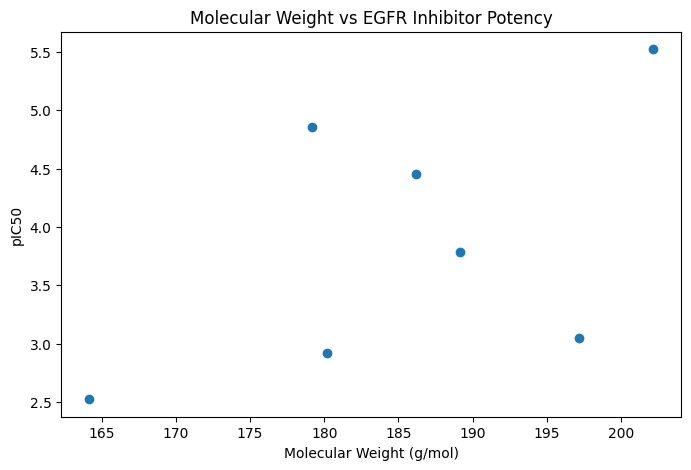

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    combined_df["Molecular_Weight"],
    combined_df["pIC50"]
)

plt.xlabel("Molecular Weight (g/mol)")
plt.ylabel("pIC50")
plt.title("Molecular Weight vs EGFR Inhibitor Potency")

plt.show()

In [53]:
combined_df.to_csv(
    "EGFR_Integrated_Research_Dataset.csv",
    index=False
)

print("Integrated dataset saved!")

Integrated dataset saved!


In [54]:
correlation = combined_df[
    [
        "Molecular_Weight",
        "LogP",
        "H_Bond_Donors",
        "H_Bond_Acceptors",
        "TPSA",
        "Rotatable_Bonds",
        "pIC50"
    ]
].corr(method="pearson")

display(correlation)

,Molecular_Weight,LogP,H_Bond_Donors,H_Bond_Acceptors,TPSA,Rotatable_Bonds,pIC50
Molecular_Weight,1.000000,-0.399766,0.500550,0.910531,0.966884,-0.194005,0.541305
LogP,-0.399766,1.000000,-0.911708,-0.243295,-0.414099,-0.744072,0.119167
H_Bond_Donors,0.500550,-0.911708,1.000000,0.419573,0.542720,0.540062,0.005664
H_Bond_Acceptors,0.910531,-0.243295,0.419573,1.000000,0.942957,-0.418330,0.675814
TPSA,0.966884,-0.414099,0.542720,0.942957,1.000000,-0.259986,0.446241
Rotatable_Bonds,-0.194005,-0.744072,0.540062,-0.418330,-0.259986,1.000000,-0.380979
pIC50,0.541305,0.119167,0.005664,0.675814,0.446241,-0.380979,1.000000


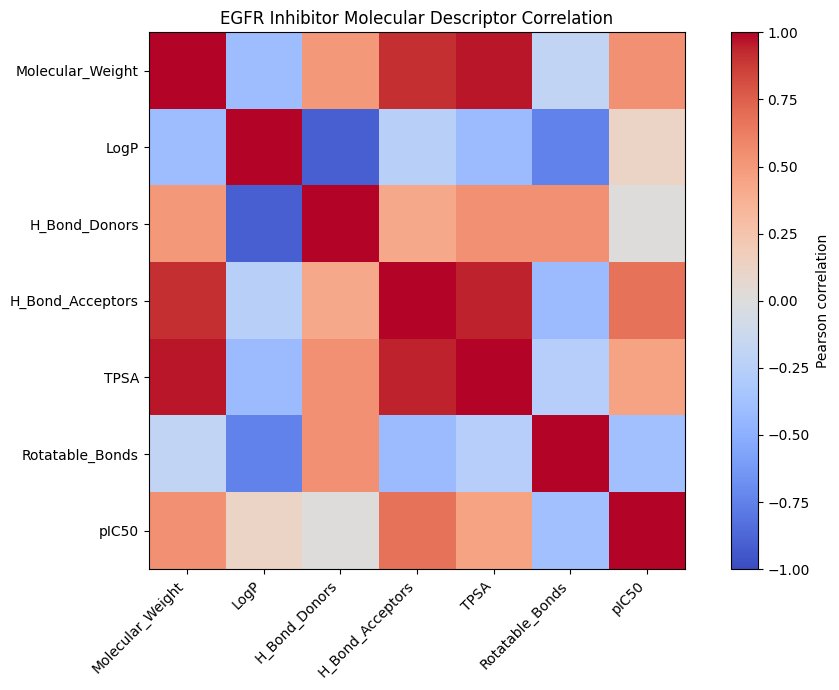

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Pearson correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("EGFR Inhibitor Molecular Descriptor Correlation")

plt.tight_layout()
plt.show()

In [56]:
pic50_corr = correlation["pIC50"].drop("pIC50")

pic50_corr = pic50_corr.sort_values(
    ascending=False
)

display(pic50_corr)

,pIC50
H_Bond_Acceptors,0.675814
Molecular_Weight,0.541305
TPSA,0.446241
LogP,0.119167
H_Bond_Donors,0.005664
Rotatable_Bonds,-0.380979


In [57]:
summary = combined_df[
    [
        "Molecular_Weight",
        "LogP",
        "TPSA",
        "pIC50"
    ]
].describe()

display(summary)

,Molecular_Weight,LogP,TPSA,pIC50
count,7.000000,7.000000,7.000000,7.000000
mean,185.456143,1.099771,83.751429,3.872093
std,12.598568,0.520032,18.034527,1.114002
min,164.160000,0.052200,57.530000,2.522879
25%,179.667000,1.005050,73.660000,2.983288
50%,186.170000,1.233960,81.320000,3.782516
75%,193.180000,1.436890,95.910000,4.654902
max,202.169000,1.528360,108.270000,5.522879


In [58]:
correlation.to_csv("EGFR_Correlation_Matrix.csv")

summary.to_csv("EGFR_Statistical_Summary.csv")

print("Statistical reports saved!")

Statistical reports saved!


In [59]:
print("Total records:", len(combined_df))

print("Unique compounds:",
      combined_df["ChEMBL_ID"].nunique())

print("Missing values:")
display(combined_df.isnull().sum())

Total records: 7
Unique compounds: 7
Missing values:


,0
ChEMBL_ID,0
standard_type,0
standard_relation,0
IC50_nM,0
standard_units,0
target_chembl_id,0
assay_chembl_id,0
pchembl_value,4
Compound_Name,0
Molecular_Weight,0


In [60]:
duplicate_counts = combined_df[
    "ChEMBL_ID"
].value_counts()

print("Compounds with repeated measurements:")
display(duplicate_counts[duplicate_counts > 1])

Compounds with repeated measurements:


,count
ChEMBL_ID,


In [61]:
import numpy as np

combined_df["calculated_pIC50"] = (
    9 - np.log10(combined_df["IC50_nM"])
)

combined_df["pIC50_difference"] = (
    combined_df["pIC50"] -
    combined_df["calculated_pIC50"]
)

display(
    combined_df[
        ["IC50_nM", "pIC50", "calculated_pIC50",
         "pIC50_difference"]
    ].head(10)
)

,IC50_nM,pIC50,calculated_pIC50,pIC50_difference
0,3000000.0,2.522879,2.522879,0.0
1,35000.0,4.455932,4.455932,0.0
2,900000.0,3.045757,3.045757,0.0
3,3000.0,5.522879,5.522879,0.0
4,165000.0,3.782516,3.782516,0.0
5,14000.0,4.853872,4.853872,0.0
6,1200000.0,2.920819,2.920819,0.0


In [62]:
print("Structures retrieved:",
      len(structure_df))

print("Unique ChEMBL IDs in structure dataset:",
      structure_df["ChEMBL_ID"].nunique())

print("Missing SMILES:",
      structure_df["SMILES"].isna().sum())

print("Missing InChIKeys:",
      structure_df["InChIKey"].isna().sum())

Structures retrieved: 9
Unique ChEMBL IDs in structure dataset: 9
Missing SMILES: 0
Missing InChIKeys: 0


In [63]:
qc_report = pd.DataFrame({
    "Metric": [
        "Total records",
        "Unique compounds",
        "Repeated compound records",
        "Missing IC50 values",
        "Missing molecular weights",
        "Missing SMILES"
    ],
    "Value": [
        len(combined_df),
        combined_df["ChEMBL_ID"].nunique(),
        int((duplicate_counts > 1).sum()),
        combined_df["IC50_nM"].isna().sum(),
        combined_df["Molecular_Weight"].isna().sum(),
        structure_df["SMILES"].isna().sum()
    ]
})

display(qc_report)

qc_report.to_csv("EGFR_Data_Quality_Report.csv", index=False)

,Metric,Value
0,Total records,7
1,Unique compounds,7
2,Repeated compound records,0
3,Missing IC50 values,0
4,Missing molecular weights,0
5,Missing SMILES,0


In [64]:
from google.colab import files

files.download("EGFR_Integrated_Research_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>